In [6]:
import numpy as np 
import os 
import xarray as xr
import fnmatch
#import aqua
import pandas as pd
import cftime 

import matplotlib.pyplot as plt

#print(aqua.__version__)

!hostname 


gs02r2b72


# concat station data

In [10]:
# notebook for concatanating caribbean island data
root_cihm = "/gpfs/scratch/bsc32/bsc032263/cimh/stations" # /RR1/daily/prlr"
var = "tmean"
file_naming_convention = f"*{var}*.nc"

stations = ["RR1", "RR2", "RR3"]

station_islands = {
    "BAR": ["RR1"],
    "GRE": ["RR2"],
    "TRI": ["RR3"],
    "TOB": ["RR4"],
    "LUC": ["RR5"]
}

new_coords = {
    "RR1": ([13.147, -59.624]), # BAR
    "RR2": ([12.007, -61.775]), # GRE
    "RR3": ([10.645, -61.399]), # TRI
    "RR4": ([11.152, -60.833]), # TOB
    "RR5": ([13.735, -60.949]), # LUC
}

for station in stations: #s.listdir(root_meteofr_stations):
    print(station)
    matching_files = []

    folder_path = os.path.join(root_cihm, station, f"daily/{var}")
 
    try:
        for filename in os.listdir(folder_path):
            if fnmatch.fnmatch(filename, file_naming_convention):
                matching_files.append(os.path.join(folder_path, filename))
        
        matching_files = sorted(matching_files)
        time_series = xr.open_dataset(matching_files[0])
        print(matching_files[0])

        # Print the sorted list of matching files
        #print("Sorted matching files:")
        #print(matching_files[1])

        for j in range(1, len(matching_files)):
            print(matching_files[j])
            new_data = xr.open_dataset(matching_files[j])
            #new_data = area_selection(new_data[var][0,:,:], lon=lon_lim, lat=lat_lim, drop=True)
            time_series = xr.concat([time_series, new_data], dim= 'time')

        time_series["tmean"] = xr.where(time_series["tmean"] < 0, np.nan, time_series.tmean)
        #time_series["lon"] = -time_series["lon"]
        
        #if station in ["RR4", "RR5"]:
        time_series["lat"] = new_coords[station][0]
        time_series["lon"] = new_coords[station][1]


        dates = time_series.time
        time_stamp_sorted = sorted(time_series.time.data)
        time_stamp_list = [pd.to_datetime(x) for x in time_stamp_sorted]
        time_str1 = time_stamp_list[0].strftime("%Y_%m_%d")
        time_str2 = time_stamp_list[-1].strftime("%Y_%m_%d")

        file_name = f'{var}_{station}_{time_str1}_to_{time_str2}.nc'

        total_path = os.path.join(folder_path, file_name)
        time_series.to_netcdf(path = total_path, mode='w')
        print(f'saved {total_path}')

    except FileNotFoundError:
        print('skip', station)



RR1
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199001.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199002.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199003.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199004.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199005.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199006.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199007.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199008.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199009.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199010.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199011.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199012.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_199101.nc
/gpfs/sc

# doing the same for prlr

In [17]:
matching_files

['/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199001.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199002.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199003.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199004.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199005.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199006.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199007.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199008.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199009.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199010.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199011.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199012.nc',
 '/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prl

In [18]:
# notebook for concatanating caribbean island data
root_cihm = "/gpfs/scratch/bsc32/bsc032263/cimh/stations" # /RR1/daily/prlr"
var = "prlr"
file_naming_convention = f"*{var}*.nc"

stations = ["RR5"]

station_islands = {
    "BAR": ["RR1"],
    "GRE": ["RR2"],
    "TRI": ["RR3"],
    "TOB": ["RR4"],
    "LUC": ["RR5"]
}

new_coords = {
    "RR1": ([13.147, -59.624]), # BAR
    "RR2": ([12.007, -61.775]), # GRE
    "RR3": ([10.645, -61.399]), # TRI
    "RR4": ([11.152, -60.833]), # TOB
    "RR5": ([13.735, -60.949]), # LUC
}

for station in stations: #s.listdir(root_meteofr_stations):
    print(station)
    matching_files = []

    folder_path = os.path.join(root_cihm, station, f"daily/{var}")
 
    try:
        for filename in os.listdir(folder_path):
            if fnmatch.fnmatch(filename, file_naming_convention):
                matching_files.append(os.path.join(folder_path, filename))
        
        matching_files = sorted(matching_files)
        time_series = xr.open_dataset(matching_files[0])
        print(matching_files[0])

        # Print the sorted list of matching files
        #print("Sorted matching files:")
        #print(matching_files[1])

        for j in range(1, len(matching_files)):
            print(matching_files[j])
            new_data = xr.open_dataset(matching_files[j])
            
            # for some reason this file is still in mm 
            if matching_files[j] == "/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199504.nc":
                new_data["prlr"] = new_data["prlr"]*(1/24)*(1/3600)*(1/1000)
            #new_data = area_selection(new_data[var][0,:,:], lon=lon_lim, lat=lat_lim, drop=True)
            time_series = xr.concat([time_series, new_data], dim= 'time')

        #time_series["tmean"] = xr.where(time_series["tmean"] < 0, np.nan, time_series.tmean)
        
        time_series["lat"] = new_coords[station][0]
        time_series["lon"] = new_coords[station][1]


        dates = time_series.time
        time_stamp_sorted = sorted(time_series.time.data)
        time_stamp_list = [pd.to_datetime(x) for x in time_stamp_sorted]
        time_str1 = time_stamp_list[0].strftime("%Y_%m_%d")
        time_str2 = time_stamp_list[-1].strftime("%Y_%m_%d")

        file_name = f'{var}_{station}_{time_str1}_to_{time_str2}.nc'

        total_path = os.path.join(folder_path, file_name)
        time_series.to_netcdf(path = total_path, mode='w')
        print(f'saved {total_path}')

    except FileNotFoundError:
        print('skip', station)



RR5
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199001.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199002.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199003.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199004.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199005.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199006.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199007.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199008.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199009.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199010.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199011.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199012.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/prlr/prlr_199101.nc
/gpfs/scratch/bsc32/bsc032263/cimh

# fixing coords 

In [ ]:
cimh_station_list = ["RR1", "RR2", "RR3", "RR4", "RR5"]
#cimh_station_list = ["RR5"]

var = "tmean"

root_cimh = "/gpfs/scratch/bsc32/bsc032263/cimh"

# new_coords = {
#     "RR1": ([13.147, -59.624]),
#     "RR2": ([12.007, -61.785]),
#     "RR3": ([10.645, -61.399]),
#     "RR4": ([11.149, -60.834]),
#     "RR5": ([13.743, -60.956]),
# }

# WRONG!! 
new_coords = {
    "RR1": ([13.147, -59.624]),
    "RR2": ([12.007, -61.775]),
    "RR3": ([10.645, -61.399]),
    "RR4": ([11.249, -60.734]),
    "RR5": ([13.843, -60.956]),
}


cimh_stations = []
for station_index, station in enumerate(cimh_station_list):
    full_path = os.path.join(root_cimh, "stations", station, f"daily/{var}/{var}_{station}_1990_01_01_to_2020_12_31.nc")
    full_path_fix = os.path.join(root_cimh, "stations", station, f"daily/{var}/{var}_{station}_1990_01_01_to_2020_12_31_fix.nc")

    print(full_path_fix)
    try:
        time_series = xr.open_dataset(full_path)
    except FileNotFoundError:
        full_path = os.path.join(root_cimh, "stations", station, f"daily/{var}/{var}_{station}_1990_02_01_to_2020_12_31.nc")

    time_series_new = time_series.assign_coords(lat = [new_coords[station][0]], lon = [new_coords[station][1]])

    # if station == "RR5":
    #     time_series_new = xr.where(time_series_new > 0.1, time_series_new/(1000  * 60 * 60 * 24) , time_series_new)

    time_series_new.to_netcdf(path = full_path_fix)
    # time_series = convert_prlr_tp(time_series)
    # cimh_stations.append([{station}, time_series])

/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR1/daily/tmean/tmean_RR1_1990_01_01_to_2020_12_31_fix.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR2/daily/tmean/tmean_RR2_1990_01_01_to_2020_12_31_fix.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR3/daily/tmean/tmean_RR3_1990_01_01_to_2020_12_31_fix.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR4/daily/tmean/tmean_RR4_1990_01_01_to_2020_12_31_fix.nc
/gpfs/scratch/bsc32/bsc032263/cimh/stations/RR5/daily/tmean/tmean_RR5_1990_01_01_to_2020_12_31_fix.nc


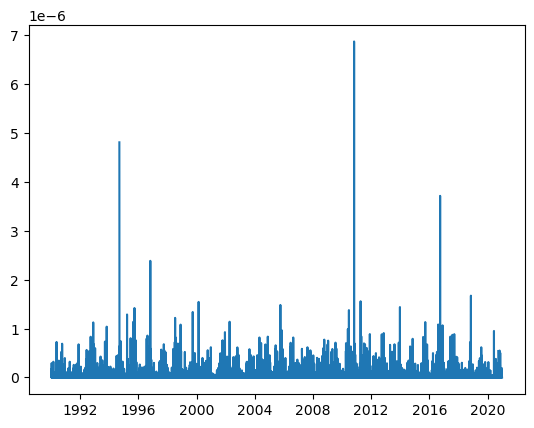

In [19]:
plt.plot(time_series.time, time_series.prlr)

In [32]:
#time_series["tmean"] = xr.where(~np.isnan(time_series["tmean"]), time_series.tmean, np.nan)

time_series["tmean"] = xr.where(time_series["tmean"] < 0, np.nan, time_series.tmean)


In [34]:
time_series["lon"] = -time_series["lon"]

In [35]:
time_series

<xarray.Dataset> Size: 136kB
Dimensions:  (time: 11323, lat: 1, lon: 1)
Coordinates:
  * lat      (lat) float32 4B 13.84
  * lon      (lon) float32 4B -60.96
  * time     (time) datetime64[ns] 91kB 1990-01-01 1990-01-02 ... 2020-12-31
Data variables:
    tmean    (time) float32 45kB 25.4 26.0 26.2 25.4 ... 26.8 26.3 26.0 26.2